In [95]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, root_mean_squared_error
from sklearn.feature_selection import f_regression, SelectKBest
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [60]:
df = pd.read_csv('data/house-prices-advanced-regression-techniques/train.csv')

In [61]:
df[['YrSold', '2ndFlrSF']].head()

,YrSold,2ndFlrSF
0,2008,854
1,2007,0
2,2008,866
3,2006,756
4,2008,1053


1. Target değişkene göre featureların grafiklerini çıkarmak: Hangi değişken daha çok etkiliyor
2. Null veri analizi, Bunları nasıl doldurucaz
3. Heatmap (ısı haritası) ile feature selection (özellik seçimi)
4. Kalite vs diğer featurelar model karşılaştırması yapıcaz
5. bütün featurelar ile model eğitimi

In [62]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [63]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [64]:
numeric_df = df.select_dtypes(include=['int64', 'float64'])

numeric_df = numeric_df.drop(columns=['Id'])

print(numeric_df)

      MSSubClass  LotFrontage  LotArea  OverallQual  OverallCond  YearBuilt  \
0             60         65.0     8450            7            5       2003   
1             20         80.0     9600            6            8       1976   
2             60         68.0    11250            7            5       2001   
3             70         60.0     9550            7            5       1915   
4             60         84.0    14260            8            5       2000   
...          ...          ...      ...          ...          ...        ...   
1455          60         62.0     7917            6            5       1999   
1456          20         85.0    13175            6            6       1978   
1457          70         66.0     9042            7            9       1941   
1458          20         68.0     9717            5            6       1950   
1459          20         75.0     9937            5            6       1965   

      YearRemodAdd  MasVnrArea  BsmtFinSF1  BsmtFin

In [65]:
y_num = numeric_df['SalePrice']
X_num = numeric_df.drop(columns=['SalePrice']) # [~numeric_df['SalePrice']]

print(X_num, y_num)

      MSSubClass  LotFrontage  LotArea  OverallQual  OverallCond  YearBuilt  \
0             60         65.0     8450            7            5       2003   
1             20         80.0     9600            6            8       1976   
2             60         68.0    11250            7            5       2001   
3             70         60.0     9550            7            5       1915   
4             60         84.0    14260            8            5       2000   
...          ...          ...      ...          ...          ...        ...   
1455          60         62.0     7917            6            5       1999   
1456          20         85.0    13175            6            6       1978   
1457          70         66.0     9042            7            9       1941   
1458          20         68.0     9717            5            6       1950   
1459          20         75.0     9937            5            6       1965   

      YearRemodAdd  MasVnrArea  BsmtFinSF1  BsmtFin

In [66]:
X_num.fillna(0,inplace=True)
y_num.fillna(0,inplace=True)

In [67]:
X_num_train, X_num_test, y_num_train, y_num_test = train_test_split(X_num, y_num, test_size=0.2, random_state=42)

print(X_num_train.shape, X_num_test.shape, y_num_train.shape, y_num_test.shape)

(1168, 36) (292, 36) (1168,) (292,)


In [68]:
model_num = LinearRegression()
model_num.fit(X_num_train, y_num_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [69]:
print("Katsayılar:", model_num.coef_)
print("Sabit (intercept):", model_num.intercept_)

# y = b + w1.x1 + w2.x2 + ...

Katsayılar: [-1.76654624e+02 -1.80730493e+01  3.94614202e-01  1.78124152e+04
  4.54665867e+03  3.40268717e+02  1.55676237e+02  2.09680437e+01
  8.56508946e+00 -1.70576357e+00 -5.90389148e-01  6.26893674e+00
  1.15842969e+01  1.45240189e+01  4.25906074e+00  3.03673765e+01
  1.08667801e+04 -1.05844398e+03  3.06139492e+03 -2.27266812e+03
 -9.11097193e+03 -1.33149799e+04  5.09136317e+03  4.75403239e+03
 -1.40769806e+01  1.64562870e+04  4.89074678e+00  2.39982086e+01
 -9.25009460e+00  9.67847252e+00  3.96376317e+01  6.48849015e+01
 -2.97226918e+01 -4.45881001e-01 -1.31444846e+02 -4.63408184e+02]
Sabit (intercept): -84812.89375784606


In [70]:
score = model_num.score(X_num_test, y_num_test) # bu R2 metodu ile score yaptı.. bunu RMSE ile yap !!

print(score)

0.8304603674991127


In [71]:
y_num_pred = model_num.predict(X_num_test)

r2_num = r2_score(y_num_test, y_num_pred)

print(r2_num)

0.8304603674991127


In [72]:
mse_num = mean_squared_error(y_num_test, y_num_pred)

print(mse_num)

1300424286.3284297


In [73]:
rmse_num = root_mean_squared_error(y_num_test, y_num_pred)

print(rmse_num)

36061.39606737972


In [74]:
mae_num = mean_absolute_error(y_num_test, y_num_pred)

print(mae_num)

22186.99060731657


In [75]:
non_numeric_df = df.select_dtypes(exclude=['int64', 'float64'])


print(non_numeric_df.info())
print(non_numeric_df.dtypes.value_counts())
print(non_numeric_df.columns)
print(non_numeric_df.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 43 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   MSZoning       1460 non-null   object
 1   Street         1460 non-null   object
 2   Alley          91 non-null     object
 3   LotShape       1460 non-null   object
 4   LandContour    1460 non-null   object
 5   Utilities      1460 non-null   object
 6   LotConfig      1460 non-null   object
 7   LandSlope      1460 non-null   object
 8   Neighborhood   1460 non-null   object
 9   Condition1     1460 non-null   object
 10  Condition2     1460 non-null   object
 11  BldgType       1460 non-null   object
 12  HouseStyle     1460 non-null   object
 13  RoofStyle      1460 non-null   object
 14  RoofMatl       1460 non-null   object
 15  Exterior1st    1460 non-null   object
 16  Exterior2nd    1460 non-null   object
 17  MasVnrType     588 non-null    object
 18  ExterQual      1460 non-null

In [76]:
df.fillna(0, inplace=True)

In [77]:
df_encoded = pd.get_dummies(df, columns=non_numeric_df.columns, drop_first=True).astype(int)

print(df_encoded)
print(df_encoded.columns)
print(df_encoded.shape)

        Id  MSSubClass  LotFrontage  LotArea  OverallQual  OverallCond  \
0        1          60           65     8450            7            5   
1        2          20           80     9600            6            8   
2        3          60           68    11250            7            5   
3        4          70           60     9550            7            5   
4        5          60           84    14260            8            5   
...    ...         ...          ...      ...          ...          ...   
1455  1456          60           62     7917            6            5   
1456  1457          20           85    13175            6            6   
1457  1458          70           66     9042            7            9   
1458  1459          20           68     9717            5            6   
1459  1460          20           75     9937            5            6   

      YearBuilt  YearRemodAdd  MasVnrArea  BsmtFinSF1  ...  SaleType_ConLI  \
0          2003          2003    

In [78]:
for i in df_encoded.columns:
    if 'SaleCondition' in i:
        print(i)

SaleCondition_AdjLand
SaleCondition_Alloca
SaleCondition_Family
SaleCondition_Normal
SaleCondition_Partial


In [79]:
y_encode = df_encoded['SalePrice']
X_encode = df_encoded.drop(columns=['SalePrice'])

X_encode_train, X_encode_test, y_encode_train, y_encode_test = train_test_split(X_encode, y_encode, test_size=0.2, random_state=42)

model_encode = LinearRegression()
model_encode.fit(X_encode_train, y_encode_train)

y_encode_pred = model_encode.predict(X_encode_test)

rmse_encode = root_mean_squared_error(y_encode_test, y_encode_pred)

print(rmse_num, rmse_encode)

36061.39606737972 83073.5495460321


In [80]:
F, p = f_regression(X_encode, y_encode)

# print(f'F: \n {F} \n\n p: \n {p}')

result = pd.DataFrame({
    "Features": X_encode.columns,
    "F_statistic": F,
    "p_value": p 
}).sort_values("F_statistic", ascending=False)

print(result)

              Features  F_statistic        p_value
4          OverallQual  2436.770591  2.185675e-313
16           GrLivArea  1470.585010  4.518034e-223
26          GarageCars  1013.705666  2.498644e-169
27          GarageArea   926.951287  5.265038e-158
12         TotalBsmtSF   880.341282  9.484229e-152
..                 ...          ...            ...
162    Foundation_Wood     0.010719   9.175528e-01
232      GarageCond_Gd     0.001409   9.700646e-01
110  RoofStyle_Mansard     0.000139   9.906085e-01
114     RoofMatl_Metal     0.000134   9.907497e-01
183   BsmtFinType2_GLQ     0.000008   9.976998e-01

[261 rows x 3 columns]


1. Anlamlı özellikleri bulmak için F_statistic ve p_value değerlerine göre filtreleme yapılacak.
2. Sonrasına sonra bakılacak.

In [81]:
selector_10 = SelectKBest(score_func=f_regression, k=10)

selector_10.fit(X_encode, y_encode)

X_encode_new_col_10 = X_encode.columns[selector_10.get_support()]

print(X_encode_new_col_10)

Index(['OverallQual', 'TotalBsmtSF', '1stFlrSF', 'GrLivArea', 'FullBath',
       'TotRmsAbvGrd', 'GarageCars', 'GarageArea', 'ExterQual_TA',
       'BsmtQual_Ex'],
      dtype='object')


In [82]:
X_encode_new_10 = X_encode[X_encode_new_col_10]

X_feature_10_train, X_feature_10_test, y_feature_10_train, y_feature_10_test = train_test_split(X_encode_new_10, y_encode, test_size=0.2, random_state=42)

In [83]:
model_feature_10 = LinearRegression()

model_feature_10.fit(X_feature_10_train, y_feature_10_train)

y_feature_10_pred = model_feature_10.predict(X_feature_10_test)

rmse_feature_10 = root_mean_squared_error(y_feature_10_test, y_feature_10_pred)

print(rmse_num, rmse_encode, rmse_feature_10)


36061.39606737972 83073.5495460321 37740.18910775935


In [84]:
selector_20 = SelectKBest(score_func=f_regression, k=20)

selector_20.fit(X_encode, y_encode)

X_encode_new_col_20 = X_encode.columns[selector_20.get_support()]

X_encode_new_20 = X_encode[X_encode_new_col_20]

X_feature_20_train, X_feature_20_test, y_feature_20_train, y_feature_20_test = train_test_split(X_encode_new_20, y_encode, test_size=0.2, random_state=42)

model_feature_20 = LinearRegression()

model_feature_20.fit(X_feature_20_train, y_feature_20_train)

y_feature_20_pred = model_feature_20.predict(X_feature_20_test)

rmse_feature_20 = root_mean_squared_error(y_feature_20_test, y_feature_20_pred)

print(rmse_num, rmse_encode, rmse_feature_10, rmse_feature_20)

36061.39606737972 83073.5495460321 37740.18910775935 35853.06599520073


In [100]:
scores = []
k_values = range(1, X_encode.shape[1] + 1)

for k in k_values:
    selector = SelectKBest(score_func=f_regression, k=k)
    X_new = selector.fit_transform(X_encode, y_encode)

    model = LinearRegression()
    cv_score = cross_val_score(model, X_new, y_encode, scoring='neg_root_mean_squared_error')
    rmse = -cv_score.mean()
    scores.append(rmse)

In [104]:
best_k = k_values[np.argmin(scores)]

print(best_k, len(scores))

139 261


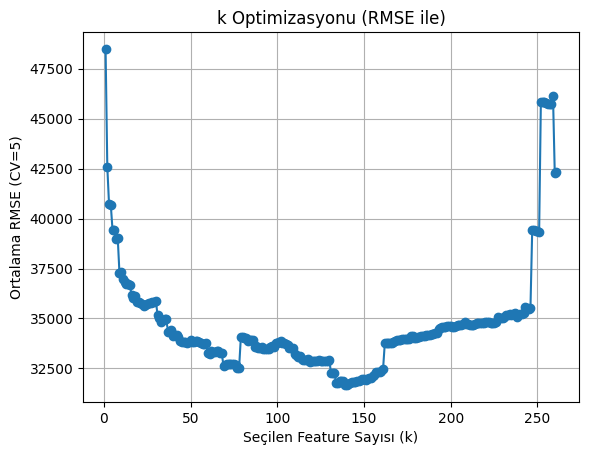

In [103]:
# Görselleştirme
plt.plot(k_values, scores, marker='o')
plt.xlabel("Seçilen Feature Sayısı (k)")
plt.ylabel("Ortalama RMSE (CV=5)")
plt.title("k Optimizasyonu (RMSE ile)")
plt.grid(True)
plt.show()